In [2]:
from google.colab import files
import pandas as pd
uploaded=files.upload()

Saving oasis_cross-sectional-5708aa0a98d82080.xlsx to oasis_cross-sectional-5708aa0a98d82080.xlsx


In [3]:
import io
file_name=next(iter(uploaded))
df=pd.read_excel(
    io.BytesIO(uploaded[file_name])
)
print("Shape",df.shape)
print(df.head())
print(df.columns.tolist())
print("\nMissing Values:")
display(df.isnull().sum())

Shape (436, 12)
              ID M/F Hand  Age  Educ  SES  MMSE  CDR  eTIV   nWBV    ASF  \
0  OAS1_0001_MR1   F    R   74   2.0  3.0  29.0  0.0  1344  0.743  1.306   
1  OAS1_0002_MR1   F    R   55   4.0  1.0  29.0  0.0  1147  0.810  1.531   
2  OAS1_0003_MR1   F    R   73   4.0  3.0  27.0  0.5  1454  0.708  1.207   
3  OAS1_0004_MR1   M    R   28   NaN  NaN   NaN  NaN  1588  0.803  1.105   
4  OAS1_0005_MR1   M    R   18   NaN  NaN   NaN  NaN  1737  0.848  1.010   

   Delay  
0    NaN  
1    NaN  
2    NaN  
3    NaN  
4    NaN  
['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']

Missing Values:


,0
ID,0
M/F,0
Hand,0
Age,0
Educ,201
SES,220
MMSE,201
CDR,201
eTIV,0
nWBV,0


In [4]:
print("CDR Values:")
print(df["CDR"].value_counts(dropna=False).sort_index())

CDR Values:
CDR
0.0    135
0.5     70
1.0     28
2.0      2
NaN    201
Name: count, dtype: int64


In [5]:
cdr_distribution=df["CDR"].value_counts(
    dropna=False,
    normalize=True
)*100
print(cdr_distribution.sort_index())

CDR
0.0    30.963303
0.5    16.055046
1.0     6.422018
2.0     0.458716
NaN    46.100917
Name: proportion, dtype: float64


In [6]:
# Compare age for CDR available vs missing
print(
    df.groupby(df["CDR"].isna())["Age"].describe()
)

       count       mean        std   min   25%   50%   75%   max
CDR                                                             
False  235.0  72.344681  12.091369  33.0  66.0  73.0  81.0  96.0
True   201.0  26.820896   9.758471  18.0  20.0  23.0  28.0  58.0


Number of duplicate rows: 0

========== NUMERICAL VARIABLES ==========
['Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']

========== DESCRIPTIVE STATISTICS ==========


,count,mean,std,min,25%,50%,75%,max
Age,436.0,51.357798,25.269862,18.000,23.00000,54.000,74.00000,96.000
Educ,235.0,3.178723,1.311510,1.000,2.00000,3.000,4.00000,5.000
SES,216.0,2.490741,1.120593,1.000,2.00000,2.000,3.00000,5.000
MMSE,235.0,27.063830,3.696870,14.000,26.00000,29.000,30.00000,30.000
CDR,235.0,0.285106,0.383405,0.000,0.00000,0.000,0.50000,2.000
eTIV,436.0,1481.919725,158.740866,1123.000,1367.75000,1475.500,1579.25000,1992.000
nWBV,436.0,0.791670,0.059937,0.644,0.74275,0.809,0.84200,0.893
ASF,436.0,1.198894,0.128682,0.881,1.11175,1.190,1.28425,1.563
Delay,20.0,20.550000,23.862490,1.000,2.75000,11.000,30.75000,89.000



========== CATEGORICAL VARIABLES ==========
['ID', 'M/F', 'Hand']

========== CATEGORICAL FREQUENCIES ==========

--- ID ---
ID
OAS1_0395_MR2    1
OAS1_0001_MR1    1
OAS1_0002_MR1    1
OAS1_0003_MR1    1
OAS1_0101_MR2    1
                ..
OAS1_0010_MR1    1
OAS1_0009_MR1    1
OAS1_0007_MR1    1
OAS1_0006_MR1    1
OAS1_0005_MR1    1
Name: count, Length: 436, dtype: int64

--- M/F ---
M/F
F    268
M    168
Name: count, dtype: int64

--- Hand ---
Hand
R    436
Name: count, dtype: int64

========== CDR DISTRIBUTION ==========
CDR
0.0    135
0.5     70
1.0     28
2.0      2
NaN    201
Name: count, dtype: int64

========== BINARY TARGET ==========
Dementia
0    135
1    100
Name: count, dtype: int64

Target percentage:
Dementia
0    57.45
1    42.55
Name: proportion, dtype: float64


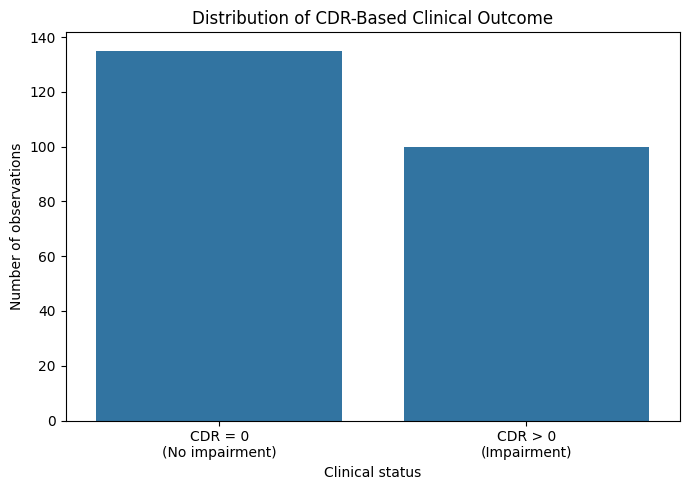

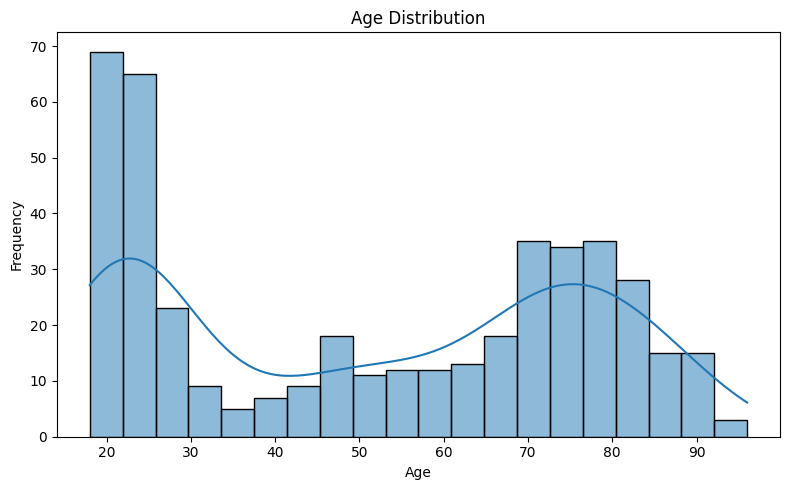

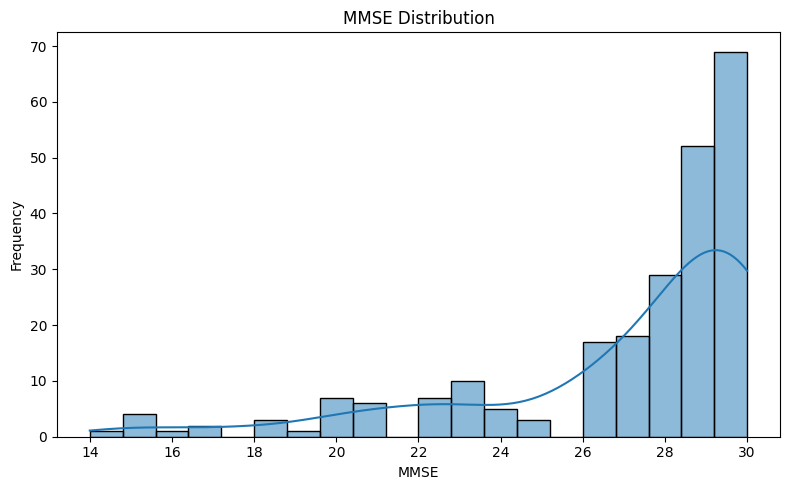

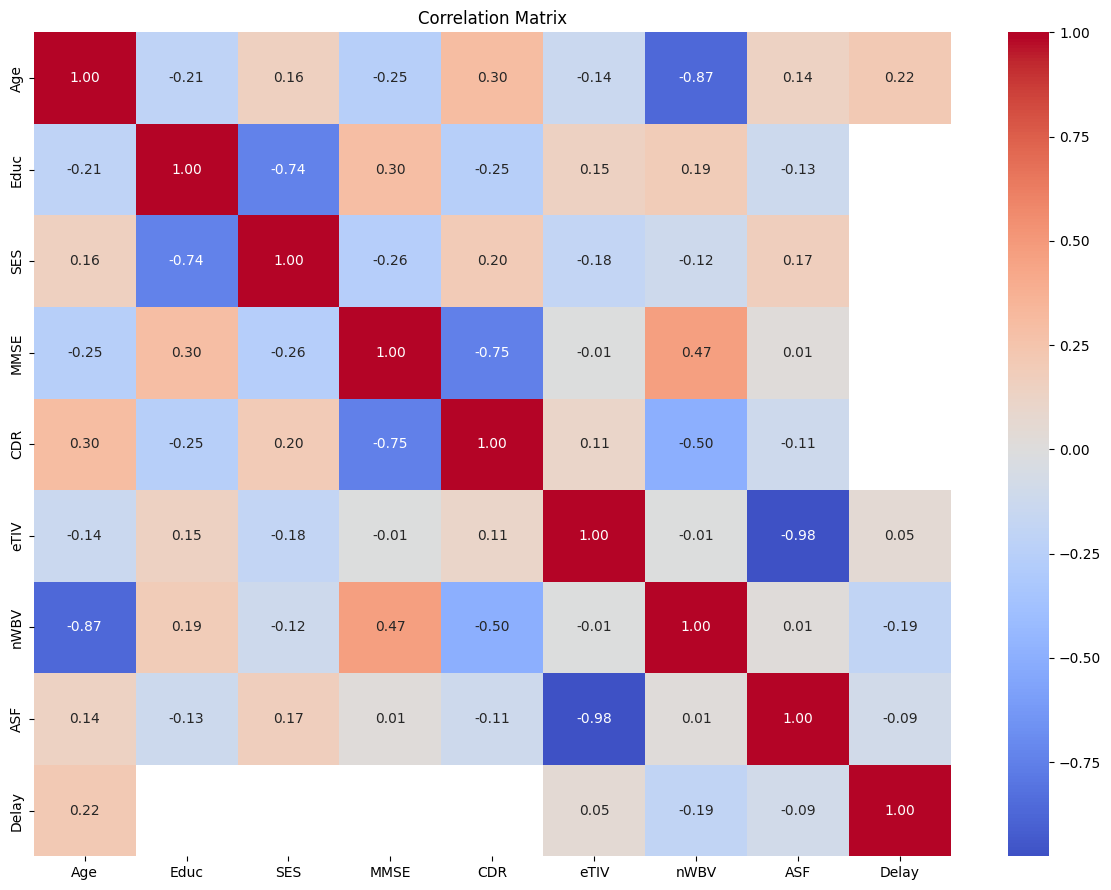


========== SUBJECT INFORMATION ==========
Total observations: 436
Unique subjects: 416
Subjects with multiple observations: 20

========== POTENTIAL TARGET VARIABLES ==========
['CDR']


STEP 1 COMPLETED
Dataset shape: (436, 13)
Number of numerical variables: 9
Number of categorical variables: 3
Duplicate rows: 0
CDR available: 235
CDR missing: 201

Next step:
Missing-data analysis + target definition + leakage audit


In [7]:
# ============================================================
# ALZHEIMER'S STATISTICAL ML PROJECT
# STEP 1: DATA LOADING & INITIAL DATA AUDIT
# Dataset: OASIS-1
# ============================================================

# -----------------------------
# 1. Import important libraries
# ----------------------------
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)


# -----------------------------
# 9. Numerical variables
# -----------------------------
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\n========== NUMERICAL VARIABLES ==========")
print(numeric_cols)


# -----------------------------
# 10. Descriptive statistics
# -----------------------------
print("\n========== DESCRIPTIVE STATISTICS ==========")

display(
    df[numeric_cols].describe().T
)


# -----------------------------
# 11. Categorical variables
# -----------------------------
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\n========== CATEGORICAL VARIABLES ==========")
print(categorical_cols)


# -----------------------------
# 12. Frequency tables
# -----------------------------
print("\n========== CATEGORICAL FREQUENCIES ==========")

for col in categorical_cols:

    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


# -----------------------------
# 13. Check CDR
# -----------------------------
print("\n========== CDR DISTRIBUTION ==========")

if "CDR" in df.columns:

    print(df["CDR"].value_counts(
        dropna=False
    ).sort_index())

else:

    print("CDR column not found.")


# -----------------------------
# 14. Create temporary binary target
# -----------------------------
if "CDR" in df.columns:

    df_model = df[df["CDR"].notna()].copy()

    # 0 = CDR 0
    # 1 = CDR > 0
    df_model["Dementia"] = (
        df_model["CDR"] > 0
    ).astype(int)

    print("\n========== BINARY TARGET ==========")

    print(
        df_model["Dementia"]
        .value_counts()
        .sort_index()
    )

    print("\nTarget percentage:")

    print(
        df_model["Dementia"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

else:

    df_model = None


# -----------------------------
# 15. Target visualization
# -----------------------------
if df_model is not None:

    plt.figure(figsize=(7, 5))

    sns.countplot(
        data=df_model,
        x="Dementia"
    )

    plt.xticks(
        [0, 1],
        [
            "CDR = 0\n(No impairment)",
            "CDR > 0\n(Impairment)"
        ]
    )

    plt.xlabel("Clinical status")
    plt.ylabel("Number of observations")
    plt.title("Distribution of CDR-Based Clinical Outcome")

    plt.tight_layout()
    plt.show()


# -----------------------------
# 16. Age distribution
# -----------------------------
if "Age" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x="Age",
        bins=20,
        kde=True
    )

    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.title("Age Distribution")

    plt.tight_layout()
    plt.show()


# -----------------------------
# 17. MMSE distribution
# -----------------------------
if "MMSE" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x="MMSE",
        bins=20,
        kde=True
    )

    plt.xlabel("MMSE")
    plt.ylabel("Frequency")
    plt.title("MMSE Distribution")

    plt.tight_layout()
    plt.show()


# -----------------------------
# 18. Correlation matrix
# -----------------------------
if len(numeric_cols) > 1:

    plt.figure(figsize=(12, 9))

    correlation = df[numeric_cols].corr()

    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )

    plt.title("Correlation Matrix")

    plt.tight_layout()
    plt.show()


# -----------------------------
# 19. Create subject ID
# -----------------------------
if "ID" in df.columns:

    df["Subject_ID"] = df["ID"].str.extract(
        r"(OAS1_\d+)"
    )[0]

    print("\n========== SUBJECT INFORMATION ==========")

    print("Total observations:", len(df))

    print(
        "Unique subjects:",
        df["Subject_ID"].nunique()
    )

    duplicate_subjects = (
        df["Subject_ID"]
        .value_counts()
    )

    print(
        "Subjects with multiple observations:",
        (duplicate_subjects > 1).sum()
    )


# -----------------------------
# 20. Potential target/leakage variables
# -----------------------------
keywords = [
    "dement",
    "alzheimer",
    "diagnos",
    "cdr",
    "clinical",
    "status",
    "class",
    "group"
]

possible_target_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in keywords
    )
]

print("\n========== POTENTIAL TARGET VARIABLES ==========")
print(possible_target_columns)


# -----------------------------
# 21. Final summary
# -----------------------------
print("\n")
print("=" * 60)
print("STEP 1 COMPLETED")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Number of numerical variables:", len(numeric_cols))
print("Number of categorical variables:", len(categorical_cols))
print("Duplicate rows:", duplicates)

if "CDR" in df.columns:
    print("CDR available:", df["CDR"].notna().sum())
    print("CDR missing:", df["CDR"].isna().sum())

print("\nNext step:")
print("Missing-data analysis + target definition + leakage audit")

Modeling dataset shape: (235, 14)

Target distribution:
Dementia
0    135
1    100
Name: count, dtype: int64

Target percentage:
Dementia
0    57.45
1    42.55
Name: proportion, dtype: float64

========== MISSING DATA ==========


,Missing_Count,Missing_Percentage
Delay,235,100.00
SES,19,8.09
M/F,0,0.00
Hand,0,0.00
Age,0,0.00
ID,0,0.00
Educ,0,0.00
MMSE,0,0.00
eTIV,0,0.00
CDR,0,0.00



========== MISSINGNESS BY OUTCOME ==========

 Educ
Dementia
0    0.0
1    0.0
Name: Educ, dtype: float64

 SES
Dementia
0     1.48
1    17.00
Name: SES, dtype: float64

 MMSE
Dementia
0    0.0
1    0.0
Name: MMSE, dtype: float64

 eTIV
Dementia
0    0.0
1    0.0
Name: eTIV, dtype: float64

 nWBV
Dementia
0    0.0
1    0.0
Name: nWBV, dtype: float64

 ASF
Dementia
0    0.0
1    0.0
Name: ASF, dtype: float64

========== GROUP COMPARISON ==========


,Variable,No_Impairment_Mean,Impairment_Mean,No_Impairment_SD,Impairment_SD,P_Value
0,Age,69.074074,76.760000,13.875582,7.119641,0.0000
1,Educ,3.444444,2.820000,1.261761,1.297861,0.0003
2,SES,2.330827,2.746988,1.064025,1.167062,0.0094
3,MMSE,29.096296,24.320000,1.125512,4.165466,0.0000
4,eTIV,1441.533333,1483.750000,152.360619,168.324025,0.0518
5,nWBV,0.769230,0.722000,0.045874,0.035801,0.0000
6,ASF,1.230667,1.197400,0.126638,0.131320,0.0516


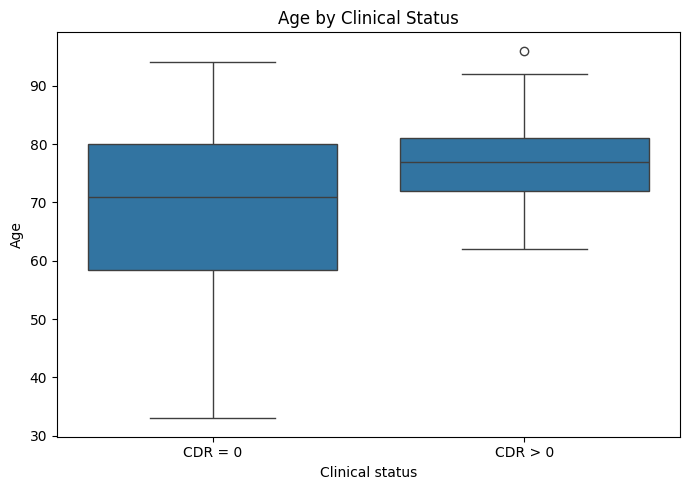

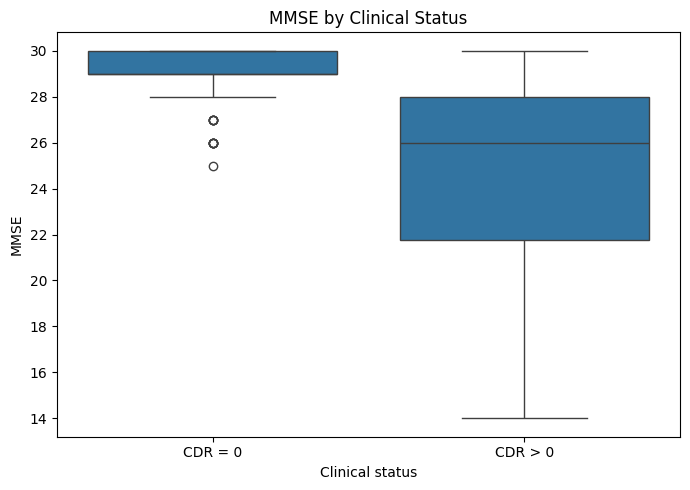

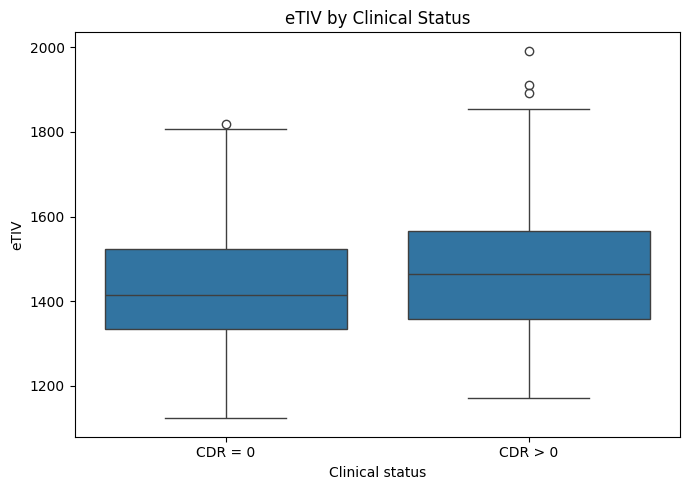

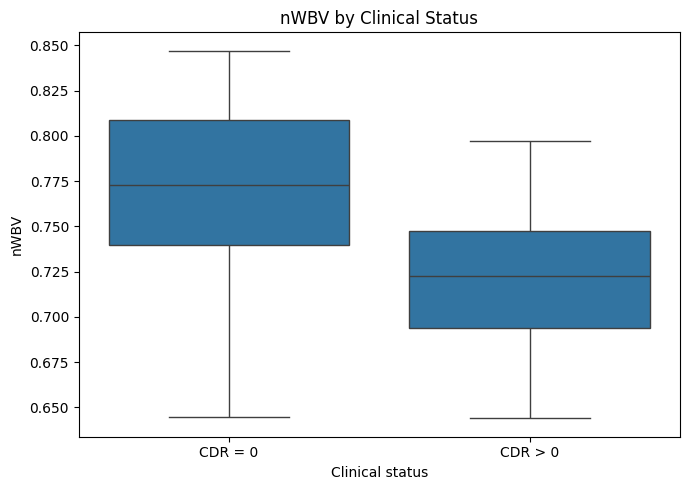

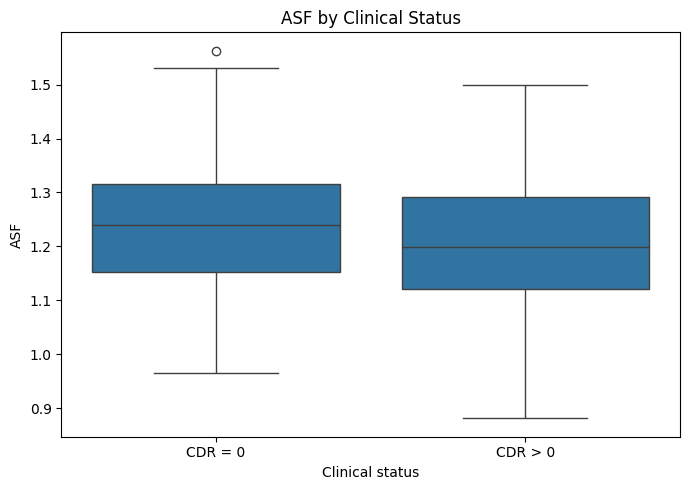


========== SEX BY OUTCOME ==========


Dementia,0,1,All
M/F,,,
F,97,59,156
M,38,41,79
All,135,100,235


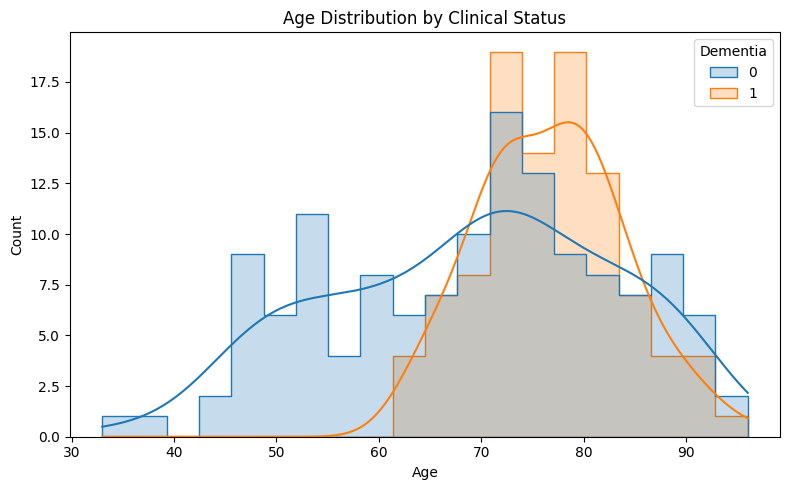

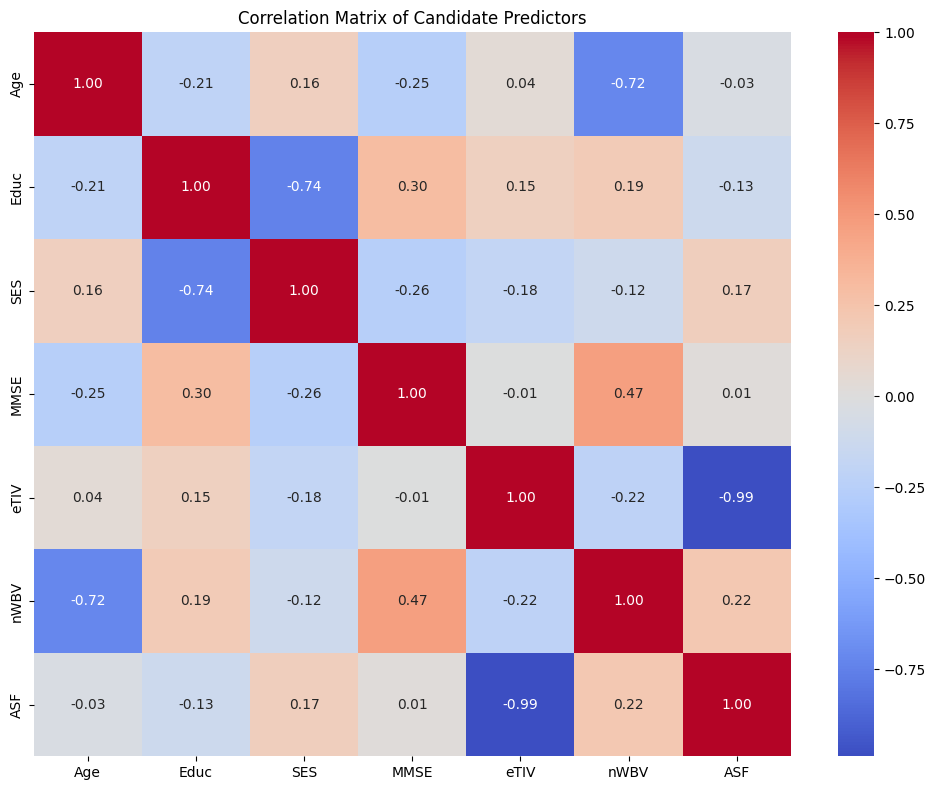


========== REPEATED SUBJECTS ==========
Subjects with multiple observations: 0


,count
Subject_ID,



========== REPEATED SUBJECT CDR CHECK ==========
Subjects with different CDR values: 0
Subjects with same CDR across observations: 235


STEP 2 COMPLETED
Observations with known CDR: 235
No impairment: 135
Clinical impairment: 100
Unique subjects: 235
Repeated subjects: 0

Candidate predictors:
['Age', 'Educ', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']

Next step: Data preprocessing + subject-level train/test split


In [8]:
# ============================================================
# ALZHEIMER'S STATISTICAL ML PROJECT
# STEP 2: MISSING DATA + STATISTICAL AUDIT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ------------------------------------------------------------
# 1. Work only with observations having known CDR
# ------------------------------------------------------------

df_model = df[df["CDR"].notna()].copy()

# Binary outcome
# 0 = CDR 0
# 1 = CDR > 0

df_model["Dementia"] = (
    df_model["CDR"] > 0
).astype(int)

print("Modeling dataset shape:", df_model.shape)

print("\nTarget distribution:")
print(df_model["Dementia"].value_counts())

print("\nTarget percentage:")
print(
    df_model["Dementia"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ------------------------------------------------------------
# 2. Missing data among modeling observations
# ------------------------------------------------------------

print("\n========== MISSING DATA ==========")

missing_model = pd.DataFrame({
    "Missing_Count":
        df_model.isnull().sum(),

    "Missing_Percentage":
        (df_model.isnull().mean() * 100).round(2)
})

display(
    missing_model.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)


# ------------------------------------------------------------
# 3. Missingness by clinical outcome
# ------------------------------------------------------------

print("\n========== MISSINGNESS BY OUTCOME ==========")

for col in [
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]:

    if col in df_model.columns:

        print("\n", col)

        result = (
            df_model
            .groupby("Dementia")[col]
            .apply(lambda x: x.isna().mean() * 100)
        )

        print(
            result.round(2)
        )


# ------------------------------------------------------------
# 4. Compare numerical variables between groups
# ------------------------------------------------------------

print("\n========== GROUP COMPARISON ==========")

numerical_predictors = [
    "Age",
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]

group_summary = []

for col in numerical_predictors:

    if col not in df_model.columns:
        continue

    group0 = df_model.loc[
        df_model["Dementia"] == 0,
        col
    ].dropna()

    group1 = df_model.loc[
        df_model["Dementia"] == 1,
        col
    ].dropna()

    group_summary.append({
        "Variable": col,

        "No_Impairment_Mean":
            group0.mean(),

        "Impairment_Mean":
            group1.mean(),

        "No_Impairment_SD":
            group0.std(),

        "Impairment_SD":
            group1.std(),

        "P_Value":
            stats.mannwhitneyu(
                group0,
                group1,
                alternative="two-sided"
            ).pvalue
    })

group_summary = pd.DataFrame(
    group_summary
)

group_summary["P_Value"] = (
    group_summary["P_Value"].round(4)
)

display(group_summary)


# ------------------------------------------------------------
# 5. Boxplots by outcome
# ------------------------------------------------------------

for col in [
    "Age",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df_model,
        x="Dementia",
        y=col
    )

    plt.xticks(
        [0, 1],
        [
            "CDR = 0",
            "CDR > 0"
        ]
    )

    plt.xlabel("Clinical status")
    plt.ylabel(col)

    plt.title(
        f"{col} by Clinical Status"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 6. Sex distribution by outcome
# ------------------------------------------------------------

print("\n========== SEX BY OUTCOME ==========")

sex_table = pd.crosstab(
    df_model["M/F"],
    df_model["Dementia"],
    margins=True
)

display(sex_table)


# ------------------------------------------------------------
# 7. Age distribution by outcome
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_model,
    x="Age",
    hue="Dementia",
    bins=20,
    kde=True,
    element="step"
)

plt.title(
    "Age Distribution by Clinical Status"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Correlation among candidate predictors
# ------------------------------------------------------------

corr_variables = [
    "Age",
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]

corr_variables = [
    x for x in corr_variables
    if x in df_model.columns
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    df_model[corr_variables].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Matrix of Candidate Predictors"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Check repeated subjects
# ------------------------------------------------------------

print("\n========== REPEATED SUBJECTS ==========")

subject_counts = (
    df_model["Subject_ID"]
    .value_counts()
)

repeated_subjects = (
    subject_counts[
        subject_counts > 1
    ]
)

print(
    "Subjects with multiple observations:",
    len(repeated_subjects)
)

display(
    repeated_subjects.head(20)
)


# ------------------------------------------------------------
# 10. Check whether repeated observations have same CDR
# ------------------------------------------------------------

print(
    "\n========== REPEATED SUBJECT CDR CHECK =========="
)

cdr_consistency = (
    df_model
    .groupby("Subject_ID")["CDR"]
    .nunique()
)

print(
    "Subjects with different CDR values:",
    (cdr_consistency > 1).sum()
)

print(
    "Subjects with same CDR across observations:",
    (cdr_consistency == 1).sum()
)


# ------------------------------------------------------------
# 11. Final audit summary
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("STEP 2 COMPLETED")
print("=" * 60)

print(
    "Observations with known CDR:",
    len(df_model)
)

print(
    "No impairment:",
    (df_model["Dementia"] == 0).sum()
)

print(
    "Clinical impairment:",
    (df_model["Dementia"] == 1).sum()
)

print(
    "Unique subjects:",
    df_model["Subject_ID"].nunique()
)

print(
    "Repeated subjects:",
    len(repeated_subjects)
)

print("\nCandidate predictors:")
print(corr_variables)

print(
    "\nNext step:"
    " Data preprocessing + subject-level train/test split"
)

In [9]:
# ============================================================
# ALZHEIMER'S STATISTICAL ML PROJECT
# STEP 3: DATA PREPROCESSING + SUBJECT-LEVEL SPLIT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 1. Create modeling dataset
# ------------------------------------------------------------

# Only observations with known CDR
df_model = df[df["CDR"].notna()].copy()

# Binary outcome
# 0 = CDR 0
# 1 = CDR > 0

df_model["Dementia"] = (
    df_model["CDR"] > 0
).astype(int)


# ------------------------------------------------------------
# 2. Remove variables that should NOT be predictors
# ------------------------------------------------------------

# CDR defines our target → leakage
# ID is an identifier
# Subject_ID is an identifier
# Hand has only one value (R) → no information
# Delay has very high missingness → exclude for now

features = [
    "M/F",
    "Age",
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]

X = df_model[features].copy()

y = df_model["Dementia"].copy()

groups = df_model["Subject_ID"].copy()


# ------------------------------------------------------------
# 3. Encode sex
# ------------------------------------------------------------

X["M/F"] = X["M/F"].map({
    "F": 0,
    "M": 1
})


# ------------------------------------------------------------
# 4. Display missing values
# ------------------------------------------------------------

print("========== MISSING VALUES ==========")

missing = pd.DataFrame({
    "Count": X.isnull().sum(),
    "Percentage":
        X.isnull().mean().mul(100).round(2)
})

display(missing)


# ------------------------------------------------------------
# 5. Check target balance
# ------------------------------------------------------------

print("\n========== TARGET ==========")

print(
    y.value_counts()
)

print("\nPercentage:")

print(
    y.value_counts(normalize=True)
      .mul(100)
      .round(2)
)


# ------------------------------------------------------------
# 6. SUBJECT-LEVEL TRAIN/TEST SPLIT
# ------------------------------------------------------------

# Get unique subjects and their outcome
subject_data = (
    df_model[
        ["Subject_ID", "Dementia"]
    ]
    .drop_duplicates("Subject_ID")
)

train_subjects, test_subjects = train_test_split(
    subject_data,
    test_size=0.20,
    random_state=42,
    stratify=subject_data["Dementia"]
)


train_ids = set(
    train_subjects["Subject_ID"]
)

test_ids = set(
    test_subjects["Subject_ID"]
)


# ------------------------------------------------------------
# 7. Create row masks
# ------------------------------------------------------------

train_mask = groups.isin(train_ids)

test_mask = groups.isin(test_ids)


X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()


# ------------------------------------------------------------
# 8. Check split
# ------------------------------------------------------------

print("\n========== DATA SPLIT ==========")

print(
    "Training observations:",
    len(X_train)
)

print(
    "Testing observations:",
    len(X_test)
)

print(
    "Training subjects:",
    len(train_ids)
)

print(
    "Testing subjects:",
    len(test_ids)
)


# ------------------------------------------------------------
# 9. Verify NO subject overlap
# ------------------------------------------------------------

overlap = train_ids.intersection(
    test_ids
)

print(
    "\nSubject overlap:",
    len(overlap)
)

if len(overlap) == 0:
    print("✓ No subject leakage detected.")
else:
    print("⚠ WARNING: Subject leakage detected!")


# ------------------------------------------------------------
# 10. Compare target distribution
# ------------------------------------------------------------

print("\n========== TARGET DISTRIBUTION ==========")

print("Training:")
print(
    y_train.value_counts()
)

print("\nTesting:")
print(
    y_test.value_counts()
)


# ------------------------------------------------------------
# 11. Save the split
# ------------------------------------------------------------

train_data = df_model[
    train_mask
].copy()

test_data = df_model[
    test_mask
].copy()

print("\nTrain dataset shape:", train_data.shape)
print("Test dataset shape:", test_data.shape)


# ------------------------------------------------------------
# 12. Final summary
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("STEP 3 COMPLETED")
print("=" * 60)

print("""
Predictors:
M/F
Age
Educ
SES
MMSE
eTIV
nWBV
ASF

Excluded:
ID        → identifier
Subject_ID → identifier
CDR       → target leakage
Hand      → no variation
Delay     → excessive missingness

Split:
80% training
20% testing
Subject-level splitting
""")

========== MISSING VALUES ==========


,Count,Percentage
M/F,0,0.00
Age,0,0.00
Educ,0,0.00
SES,19,8.09
MMSE,0,0.00
eTIV,0,0.00
nWBV,0,0.00
ASF,0,0.00



========== TARGET ==========
Dementia
0    135
1    100
Name: count, dtype: int64

Percentage:
Dementia
0    57.45
1    42.55
Name: proportion, dtype: float64

========== DATA SPLIT ==========
Training observations: 188
Testing observations: 47
Training subjects: 188
Testing subjects: 47

Subject overlap: 0
✓ No subject leakage detected.

========== TARGET DISTRIBUTION ==========
Training:
Dementia
0    108
1     80
Name: count, dtype: int64

Testing:
Dementia
0    27
1    20
Name: count, dtype: int64

Train dataset shape: (188, 14)
Test dataset shape: (47, 14)


STEP 3 COMPLETED

Predictors:
M/F
Age
Educ
SES
MMSE
eTIV
nWBV
ASF

Excluded:
ID        → identifier
Subject_ID → identifier
CDR       → target leakage
Hand      → no variation
Delay     → excessive missingness

Split:
80% training
20% testing
Subject-level splitting



Logistic Regression trained successfully!

========== LOGISTIC REGRESSION RESULTS ==========
Accuracy    : 0.7872
Precision   : 0.7778
Sensitivity : 0.7000
F1 Score    : 0.7368
ROC-AUC     : 0.9056

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

     CDR = 0       0.79      0.85      0.82        27
     CDR > 0       0.78      0.70      0.74        20

    accuracy                           0.79        47
   macro avg       0.79      0.78      0.78        47
weighted avg       0.79      0.79      0.79        47


========== CONFUSION MATRIX ==========
[[23  4]
 [ 6 14]]


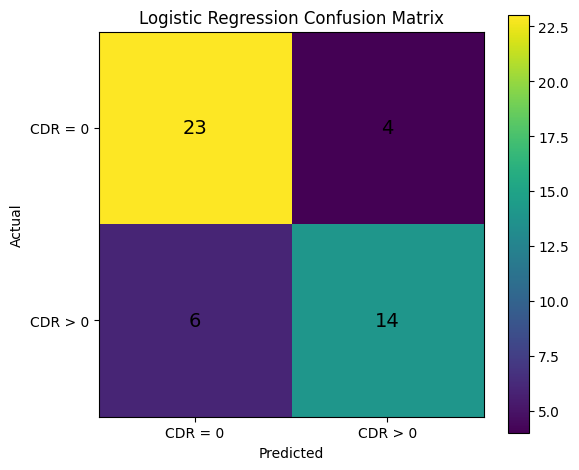

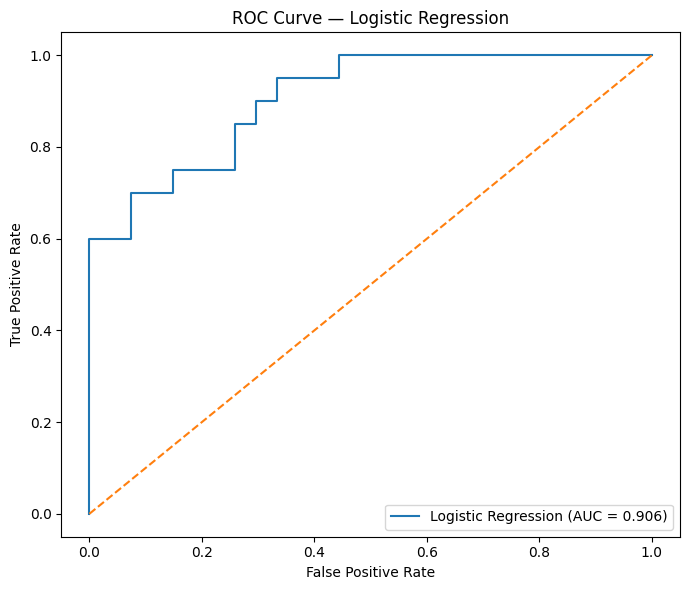


========== MODEL COEFFICIENTS ==========


,Feature,Coefficient,Odds_Ratio
5,eTIV,0.191100,1.210580
0,M/F,0.133410,1.142719
7,ASF,0.065611,1.067811
3,SES,-0.024071,0.976217
1,Age,-0.173516,0.840703
2,Educ,-0.197867,0.820479
6,nWBV,-0.749128,0.472779
4,MMSE,-2.605147,0.073892



========== MODEL SUMMARY ==========


,Model,Accuracy,Precision,Sensitivity,F1,ROC_AUC
0,Logistic Regression,0.7872,0.7778,0.7,0.7368,0.9056


In [11]:
# ============================================================
# ALZHEIMER'S STATISTICAL ML PROJECT
# STEP 4: LOGISTIC REGRESSION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)


# ------------------------------------------------------------
# 1. Prepare training and testing data
# ------------------------------------------------------------

features = [
    "M/F",
    "Age",
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]

X_train = train_data[features].copy()
X_test = test_data[features].copy()

y_train = train_data["Dementia"].copy()
y_test = test_data["Dementia"].copy()


# ------------------------------------------------------------
# 2. Encode sex
# ------------------------------------------------------------

X_train["M/F"] = X_train["M/F"].map({
    "F": 0,
    "M": 1
})

X_test["M/F"] = X_test["M/F"].map({
    "F": 0,
    "M": 1
})


# ------------------------------------------------------------
# 3. Create Logistic Regression pipeline
# ------------------------------------------------------------

logistic_model = Pipeline([

    # Fill missing SES using training-set median
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    # Standardize numerical variables
    (
        "scaler",
        StandardScaler()
    ),

    # Logistic regression
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])


# ------------------------------------------------------------
# 4. Train model
# ------------------------------------------------------------

logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression trained successfully!")


# ------------------------------------------------------------
# 5. Predictions
# ------------------------------------------------------------

y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(
    X_test
)[:, 1]


# ------------------------------------------------------------
# 6. Calculate performance metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

sensitivity = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

auc = roc_auc_score(
    y_test,
    y_prob
)


# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n========== LOGISTIC REGRESSION RESULTS ==========")

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Sensitivity : {sensitivity:.4f}")
print(f"F1 Score    : {f1:.4f}")
print(f"ROC-AUC     : {auc:.4f}")


# ------------------------------------------------------------
# 8. Classification report
# ------------------------------------------------------------

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "CDR = 0",
            "CDR > 0"
        ]
    )
)


# ------------------------------------------------------------
# 9. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n========== CONFUSION MATRIX ==========")
print(cm)


plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["CDR = 0", "CDR > 0"]
)

plt.yticks(
    [0, 1],
    ["CDR = 0", "CDR > 0"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. ROC curve
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — Logistic Regression"
)

plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Examine regression coefficients
# ------------------------------------------------------------

model = logistic_model.named_steps["model"]

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_[0]
})

coefficients["Odds_Ratio"] = np.exp(
    coefficients["Coefficient"]
)

coefficients = coefficients.sort_values(
    "Coefficient",
    ascending=False
)

print("\n========== MODEL COEFFICIENTS ==========")

display(coefficients)


# ------------------------------------------------------------
# 12. Final result table
# ------------------------------------------------------------

results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Sensitivity": [sensitivity],
    "F1": [f1],
    "ROC_AUC": [auc]
})

print("\n========== MODEL SUMMARY ==========")

display(
    results.round(4)
)

Random Forest trained successfully!

========== RANDOM FOREST RESULTS ==========
Accuracy    : 0.8085
Precision   : 0.7895
Sensitivity : 0.7500
F1 Score    : 0.7692
ROC-AUC     : 0.9296

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

     CDR = 0       0.82      0.85      0.84        27
     CDR > 0       0.79      0.75      0.77        20

    accuracy                           0.81        47
   macro avg       0.81      0.80      0.80        47
weighted avg       0.81      0.81      0.81        47


========== CONFUSION MATRIX ==========
[[23  4]
 [ 5 15]]


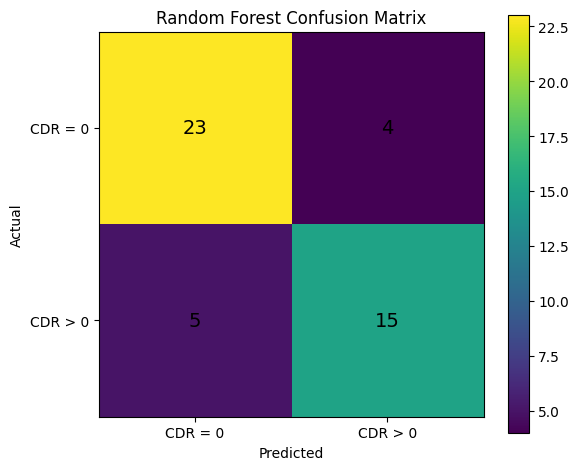


========== FEATURE IMPORTANCE ==========


,Feature,Importance
4,MMSE,0.388652
6,nWBV,0.183640
1,Age,0.154852
5,eTIV,0.083983
7,ASF,0.083917
2,Educ,0.051687
3,SES,0.031192
0,M/F,0.022077


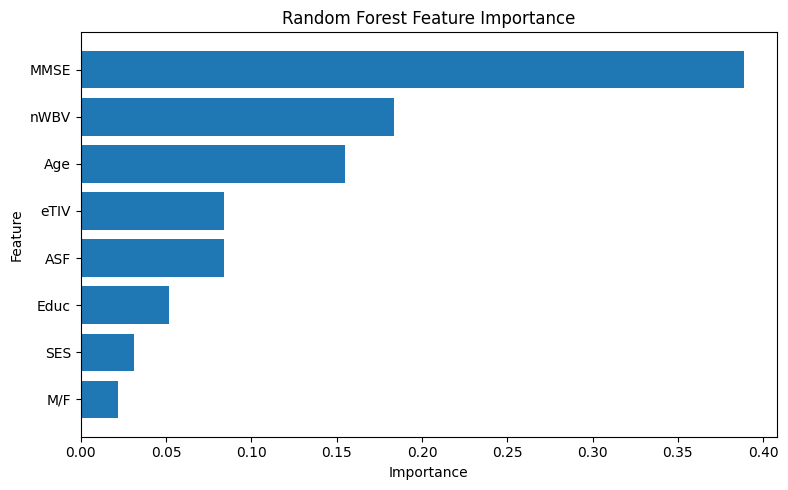

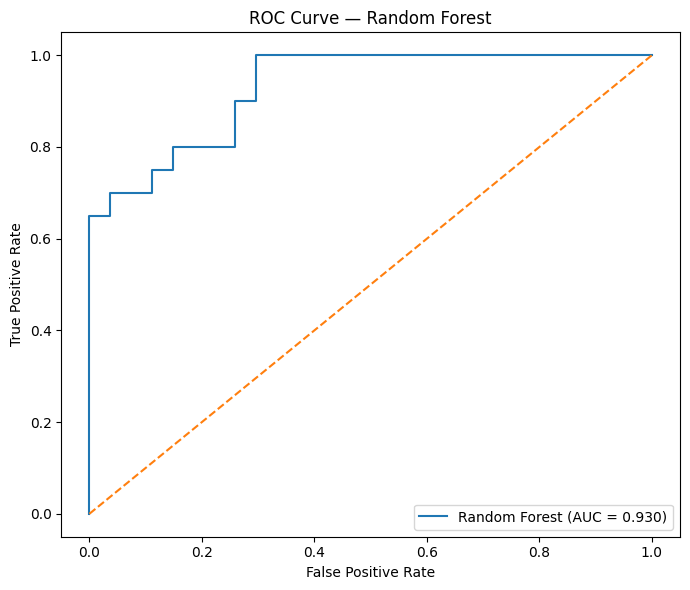


========== MODEL COMPARISON ==========


,Model,Accuracy,Precision,Sensitivity,F1,ROC_AUC
0,Logistic Regression,0.7872,0.7778,0.70,0.7368,0.9056
1,Random Forest,0.8085,0.7895,0.75,0.7692,0.9296


In [12]:
# ============================================================
# STEP 5: RANDOM FOREST CLASSIFIER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)


# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

features = [
    "M/F",
    "Age",
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]

X_train_rf = train_data[features].copy()
X_test_rf = test_data[features].copy()

y_train_rf = train_data["Dementia"].copy()
y_test_rf = test_data["Dementia"].copy()


# ------------------------------------------------------------
# 2. Encode sex
# ------------------------------------------------------------

X_train_rf["M/F"] = X_train_rf["M/F"].map({
    "F": 0,
    "M": 1
})

X_test_rf["M/F"] = X_test_rf["M/F"].map({
    "F": 0,
    "M": 1
})


# ------------------------------------------------------------
# 3. Random Forest pipeline
# ------------------------------------------------------------

rf_model = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            class_weight="balanced"
        )
    )
])


# ------------------------------------------------------------
# 4. Train
# ------------------------------------------------------------

rf_model.fit(
    X_train_rf,
    y_train_rf
)

print("Random Forest trained successfully!")


# ------------------------------------------------------------
# 5. Predictions
# ------------------------------------------------------------

y_pred_rf = rf_model.predict(
    X_test_rf
)

y_prob_rf = rf_model.predict_proba(
    X_test_rf
)[:, 1]


# ------------------------------------------------------------
# 6. Performance metrics
# ------------------------------------------------------------

accuracy_rf = accuracy_score(
    y_test_rf,
    y_pred_rf
)

precision_rf = precision_score(
    y_test_rf,
    y_pred_rf
)

recall_rf = recall_score(
    y_test_rf,
    y_pred_rf
)

f1_rf = f1_score(
    y_test_rf,
    y_pred_rf
)

auc_rf = roc_auc_score(
    y_test_rf,
    y_prob_rf
)


# ------------------------------------------------------------
# 7. Results
# ------------------------------------------------------------

print("\n========== RANDOM FOREST RESULTS ==========")

print(f"Accuracy    : {accuracy_rf:.4f}")
print(f"Precision   : {precision_rf:.4f}")
print(f"Sensitivity : {recall_rf:.4f}")
print(f"F1 Score    : {f1_rf:.4f}")
print(f"ROC-AUC     : {auc_rf:.4f}")


# ------------------------------------------------------------
# 8. Classification report
# ------------------------------------------------------------

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test_rf,
        y_pred_rf,
        target_names=[
            "CDR = 0",
            "CDR > 0"
        ]
    )
)


# ------------------------------------------------------------
# 9. Confusion matrix
# ------------------------------------------------------------

cm_rf = confusion_matrix(
    y_test_rf,
    y_pred_rf
)

print("\n========== CONFUSION MATRIX ==========")
print(cm_rf)


plt.figure(figsize=(6, 5))

plt.imshow(cm_rf)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["CDR = 0", "CDR > 0"]
)

plt.yticks(
    [0, 1],
    ["CDR = 0", "CDR > 0"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm_rf[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Feature importance
# ------------------------------------------------------------

rf = rf_model.named_steps["model"]

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\n========== FEATURE IMPORTANCE ==========")

display(importance)


# ------------------------------------------------------------
# 11. Feature importance plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Random Forest Feature Importance"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. ROC curve
# ------------------------------------------------------------

fpr_rf, tpr_rf, _ = roc_curve(
    y_test_rf,
    y_prob_rf
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — Random Forest"
)

plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Compare with Logistic Regression
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy,
        accuracy_rf
    ],

    "Precision": [
        precision,
        precision_rf
    ],

    "Sensitivity": [
        sensitivity,
        recall_rf
    ],

    "F1": [
        f1,
        f1_rf
    ],

    "ROC_AUC": [
        auc,
        auc_rf
    ]
})

print("\n========== MODEL COMPARISON ==========")

display(
    comparison.round(4)
)

Negative class: 108
Positive class: 80
Scale_pos_weight: 1.35

XGBoost trained successfully!

========== XGBOOST RESULTS ==========
Accuracy    : 0.8085
Precision   : 0.7895
Sensitivity : 0.7500
F1 Score    : 0.7692
ROC-AUC     : 0.9333

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

     CDR = 0       0.82      0.85      0.84        27
     CDR > 0       0.79      0.75      0.77        20

    accuracy                           0.81        47
   macro avg       0.81      0.80      0.80        47
weighted avg       0.81      0.81      0.81        47


========== CONFUSION MATRIX ==========
[[23  4]
 [ 5 15]]


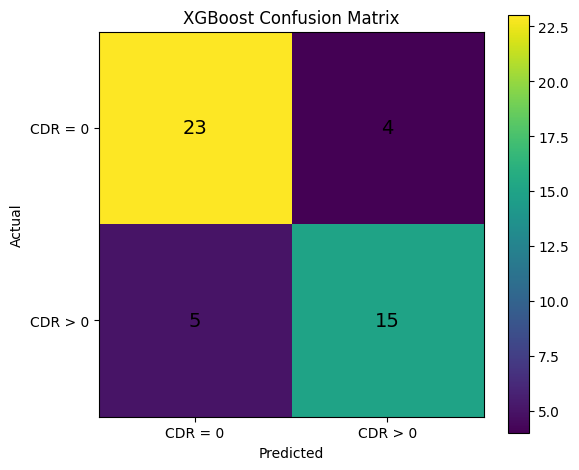


========== XGBOOST FEATURE IMPORTANCE ==========


,Feature,Importance
4,MMSE,0.438965
6,nWBV,0.122624
1,Age,0.100737
0,M/F,0.074501
2,Educ,0.071086
3,SES,0.066331
5,eTIV,0.063737
7,ASF,0.062019


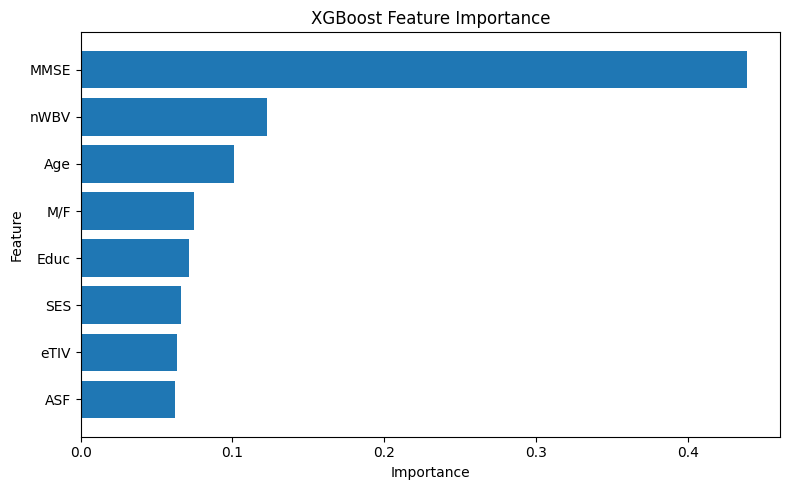

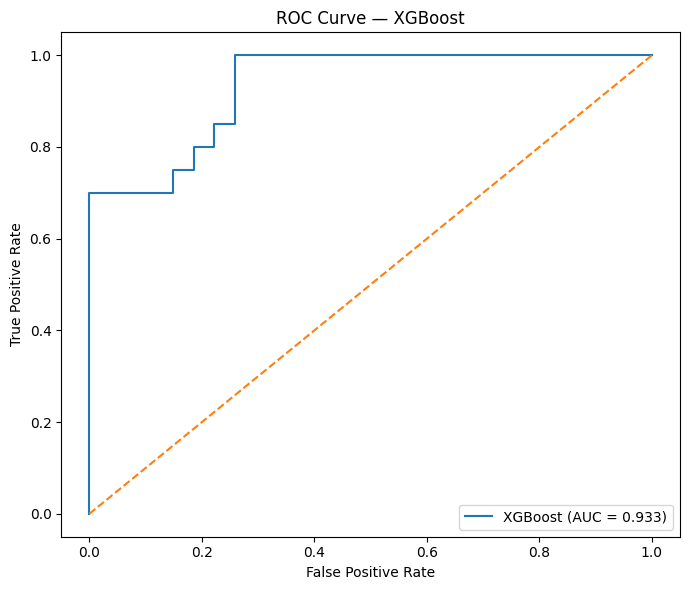


========== COMPLETE MODEL COMPARISON ==========


,Model,Accuracy,Precision,Sensitivity,F1,ROC_AUC
0,Logistic Regression,0.7872,0.7778,0.70,0.7368,0.9056
1,Random Forest,0.8085,0.7895,0.75,0.7692,0.9296
2,XGBoost,0.8085,0.7895,0.75,0.7692,0.9333


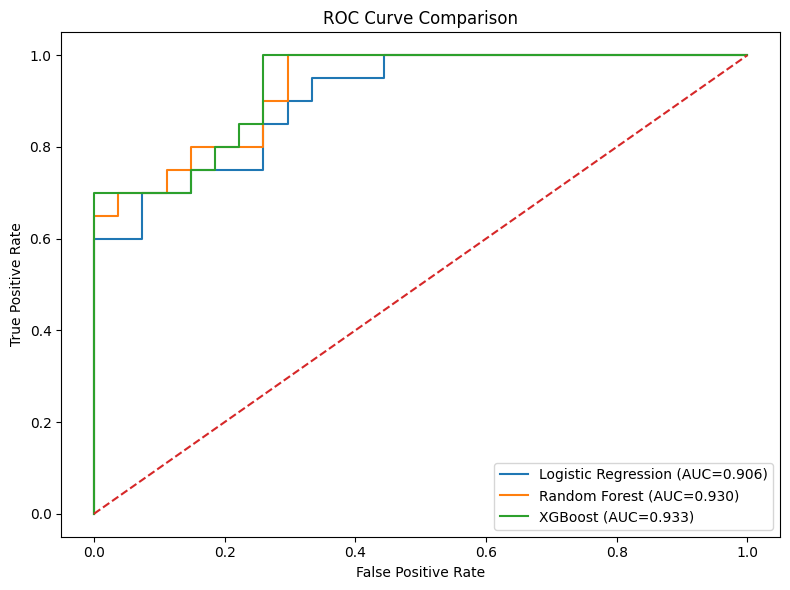



STEP 6 COMPLETED

Models evaluated:

1. Logistic Regression
2. Random Forest
3. XGBoost

Next:
Cross-validation + Bootstrap Confidence Intervals



In [13]:
# ============================================================
# ALZHEIMER'S STATISTICAL ML PROJECT
# STEP 6: XGBOOST CLASSIFIER
# ============================================================

# If XGBoost is not installed, run this automatically
!pip -q install xgboost


# ------------------------------------------------------------
# 1. Import libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from xgboost import XGBClassifier


# ------------------------------------------------------------
# 2. Prepare training and testing data
# ------------------------------------------------------------

features = [
    "M/F",
    "Age",
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]

X_train_xgb = train_data[features].copy()
X_test_xgb = test_data[features].copy()

y_train_xgb = train_data["Dementia"].copy()
y_test_xgb = test_data["Dementia"].copy()


# ------------------------------------------------------------
# 3. Encode sex
# ------------------------------------------------------------

X_train_xgb["M/F"] = X_train_xgb["M/F"].map({
    "F": 0,
    "M": 1
})

X_test_xgb["M/F"] = X_test_xgb["M/F"].map({
    "F": 0,
    "M": 1
})


# ------------------------------------------------------------
# 4. Handle missing values
# ------------------------------------------------------------

imputer_xgb = SimpleImputer(
    strategy="median"
)

X_train_xgb = imputer_xgb.fit_transform(
    X_train_xgb
)

X_test_xgb = imputer_xgb.transform(
    X_test_xgb
)


# ------------------------------------------------------------
# 5. Calculate class imbalance
# ------------------------------------------------------------

negative = (y_train_xgb == 0).sum()
positive = (y_train_xgb == 1).sum()

scale_pos_weight = negative / positive

print("Negative class:", negative)
print("Positive class:", positive)
print(
    "Scale_pos_weight:",
    round(scale_pos_weight, 3)
)


# ------------------------------------------------------------
# 6. Create XGBoost model
# ------------------------------------------------------------

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 7. Train model
# ------------------------------------------------------------

xgb_model.fit(
    X_train_xgb,
    y_train_xgb
)

print("\nXGBoost trained successfully!")


# ------------------------------------------------------------
# 8. Predictions
# ------------------------------------------------------------

y_pred_xgb = xgb_model.predict(
    X_test_xgb
)

y_prob_xgb = xgb_model.predict_proba(
    X_test_xgb
)[:, 1]


# ------------------------------------------------------------
# 9. Calculate performance metrics
# ------------------------------------------------------------

accuracy_xgb = accuracy_score(
    y_test_xgb,
    y_pred_xgb
)

precision_xgb = precision_score(
    y_test_xgb,
    y_pred_xgb
)

recall_xgb = recall_score(
    y_test_xgb,
    y_pred_xgb
)

f1_xgb = f1_score(
    y_test_xgb,
    y_pred_xgb
)

auc_xgb = roc_auc_score(
    y_test_xgb,
    y_prob_xgb
)


# ------------------------------------------------------------
# 10. Display results
# ------------------------------------------------------------

print("\n========== XGBOOST RESULTS ==========")

print(
    f"Accuracy    : {accuracy_xgb:.4f}"
)

print(
    f"Precision   : {precision_xgb:.4f}"
)

print(
    f"Sensitivity : {recall_xgb:.4f}"
)

print(
    f"F1 Score    : {f1_xgb:.4f}"
)

print(
    f"ROC-AUC     : {auc_xgb:.4f}"
)


# ------------------------------------------------------------
# 11. Classification report
# ------------------------------------------------------------

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test_xgb,
        y_pred_xgb,
        target_names=[
            "CDR = 0",
            "CDR > 0"
        ]
    )
)


# ------------------------------------------------------------
# 12. Confusion matrix
# ------------------------------------------------------------

cm_xgb = confusion_matrix(
    y_test_xgb,
    y_pred_xgb
)

print("\n========== CONFUSION MATRIX ==========")

print(cm_xgb)


plt.figure(figsize=(6, 5))

plt.imshow(cm_xgb)

plt.title(
    "XGBoost Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["CDR = 0", "CDR > 0"]
)

plt.yticks(
    [0, 1],
    ["CDR = 0", "CDR > 0"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm_xgb[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 13. Feature importance
# ------------------------------------------------------------

importance_xgb = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

importance_xgb = importance_xgb.sort_values(
    "Importance",
    ascending=False
)

print("\n========== XGBOOST FEATURE IMPORTANCE ==========")

display(
    importance_xgb
)


# ------------------------------------------------------------
# 14. Feature importance plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.barh(
    importance_xgb["Feature"],
    importance_xgb["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "XGBoost Feature Importance"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 15. ROC Curve
# ------------------------------------------------------------

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test_xgb,
    y_prob_xgb
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {auc_xgb:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve — XGBoost"
)

plt.legend()

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 16. Compare all three models
# ------------------------------------------------------------

comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy,
        accuracy_rf,
        accuracy_xgb
    ],

    "Precision": [
        precision,
        precision_rf,
        precision_xgb
    ],

    "Sensitivity": [
        sensitivity,
        recall_rf,
        recall_xgb
    ],

    "F1": [
        f1,
        f1_rf,
        f1_xgb
    ],

    "ROC_AUC": [
        auc,
        auc_rf,
        auc_xgb
    ]
})


print("\n========== COMPLETE MODEL COMPARISON ==========")

display(
    comparison.round(4)
)


# ------------------------------------------------------------
# 17. Compare ROC curves
# ------------------------------------------------------------

fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_prob
)

fpr_rf_plot, tpr_rf_plot, _ = roc_curve(
    y_test_rf,
    y_prob_rf
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC={auc:.3f})"
)

plt.plot(
    fpr_rf_plot,
    tpr_rf_plot,
    label=f"Random Forest (AUC={auc_rf:.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC={auc_xgb:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve Comparison"
)

plt.legend()

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 18. Final summary
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("STEP 6 COMPLETED")
print("=" * 60)

print("""
Models evaluated:

1. Logistic Regression
2. Random Forest
3. XGBoost

Next:
Cross-validation + Bootstrap Confidence Intervals
""")

In [15]:
# ============================================================
# STEP 7: 5-FOLD CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier


# ------------------------------------------------------------
# 1. Prepare complete labeled dataset
# ------------------------------------------------------------

features = [
    "M/F",
    "Age",
    "Educ",
    "SES",
    "MMSE",
    "eTIV",
    "nWBV",
    "ASF"
]

X_cv = df_model[features].copy()
y_cv = df_model["Dementia"].copy()


# ------------------------------------------------------------
# 2. Encode sex
# ------------------------------------------------------------

X_cv["M/F"] = X_cv["M/F"].map({
    "F": 0,
    "M": 1
})


# ------------------------------------------------------------
# 3. Define models
# ------------------------------------------------------------

logistic_cv = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


rf_cv = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("model", RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        class_weight="balanced"
    ))
])


xgb_cv = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])


models = {
    "Logistic Regression": logistic_cv,
    "Random Forest": rf_cv,
    "XGBoost": xgb_cv
}


# ------------------------------------------------------------
# 4. Create 5-fold stratified CV
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# 5. Evaluation metrics
# ------------------------------------------------------------

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "sensitivity": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


# ------------------------------------------------------------
# 6. Run cross-validation
# ------------------------------------------------------------

results_cv = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_cv,
        y_cv,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results_cv.append({
        "Model": name,

        "Accuracy_Mean":
            scores["test_accuracy"].mean(),

        "Accuracy_SD":
            scores["test_accuracy"].std(),

        "Precision_Mean":
            scores["test_precision"].mean(),

        "Sensitivity_Mean":
            scores["test_sensitivity"].mean(),

        "F1_Mean":
            scores["test_f1"].mean(),

        "ROC_AUC_Mean":
            scores["test_roc_auc"].mean(),

        "ROC_AUC_SD":
            scores["test_roc_auc"].std()
    })


# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

cv_results = pd.DataFrame(results_cv)

print("\n========== 5-FOLD CROSS-VALIDATION RESULTS ==========")

display(
    cv_results.round(4)
)


# ------------------------------------------------------------
# 8. Detailed fold-wise AUC
# ------------------------------------------------------------

print("\n========== FOLD-WISE ROC-AUC ==========")

for name, model in models.items():

    scores = cross_validate(
        model,
        X_cv,
        y_cv,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    print(
        f"\n{name}:"
    )

    print(
        np.round(
            scores["test_score"],
            4
        )
    )


# ------------------------------------------------------------
# 9. Identify best model by CV AUC
# ------------------------------------------------------------

best_model = cv_results.loc[
    cv_results["ROC_AUC_Mean"].idxmax(),
    "Model"
]

best_auc = cv_results.loc[
    cv_results["ROC_AUC_Mean"].idxmax(),
    "ROC_AUC_Mean"
]

print("\n==========================================")
print("BEST MODEL BASED ON MEAN CV ROC-AUC")
print("==========================================")

print(
    "Model:",
    best_model
)

print(
    "Mean CV ROC-AUC:",
    round(best_auc, 4)
)


# ------------------------------------------------------------
# 10. Final interpretation
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("STEP 7 COMPLETED")
print("=" * 60)

print("""
5-fold stratified cross-validation was performed.

Models:
1. Logistic Regression
2. Random Forest
3. XGBoost

Primary comparison metric:
ROC-AUC

The cross-validation results provide a more reliable
estimate of model performance than a single train/test split.
""")


========== 5-FOLD CROSS-VALIDATION RESULTS ==========


,Model,Accuracy_Mean,Accuracy_SD,Precision_Mean,Sensitivity_Mean,F1_Mean,ROC_AUC_Mean,ROC_AUC_SD
0,Logistic Regression,0.8170,0.0548,0.8237,0.73,0.7665,0.9030,0.0348
1,Random Forest,0.8255,0.0434,0.8293,0.77,0.7890,0.9063,0.0339
2,XGBoost,0.8128,0.0678,0.7982,0.76,0.7735,0.9074,0.0304



========== FOLD-WISE ROC-AUC ==========

Logistic Regression:
[0.9315 0.8778 0.9444 0.85   0.9111]

Random Forest:
[0.9167 0.8741 0.9389 0.8593 0.9426]

XGBoost:
[0.9019 0.887  0.9593 0.8704 0.9185]

BEST MODEL BASED ON MEAN CV ROC-AUC
Model: XGBoost
Mean CV ROC-AUC: 0.9074


STEP 7 COMPLETED

5-fold stratified cross-validation was performed.

Models:
1. Logistic Regression
2. Random Forest
3. XGBoost

Primary comparison metric:
ROC-AUC

The cross-validation results provide a more reliable
estimate of model performance than a single train/test split.




========== BOOTSTRAP AUC RESULTS ==========


,Model,Observed_AUC,Bootstrap_Mean_AUC,95%_CI_Lower,95%_CI_Upper,Bootstrap_SD
0,Logistic Regression,0.9056,0.9060,0.8084,0.9732,0.0425
1,Random Forest,0.9296,0.9298,0.8485,0.9827,0.0349
2,XGBoost,0.9333,0.9333,0.8549,0.9852,0.0340


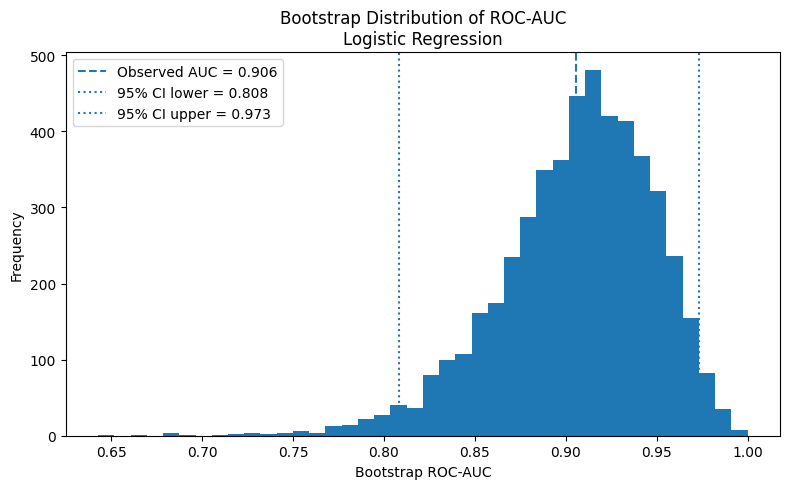

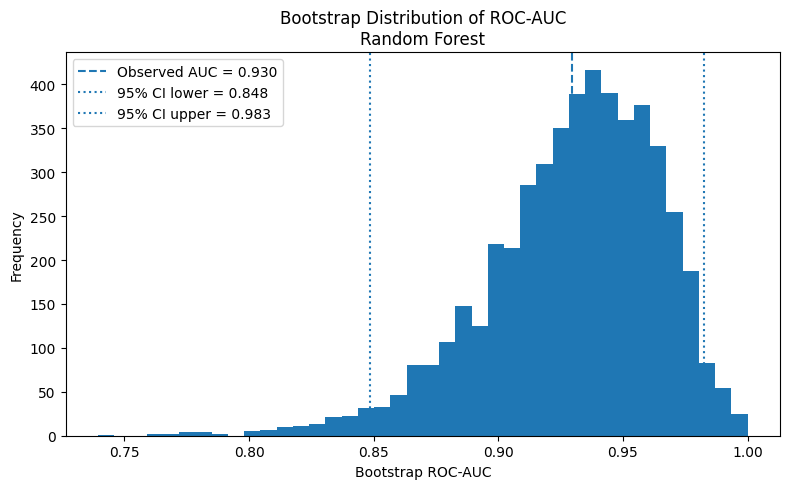

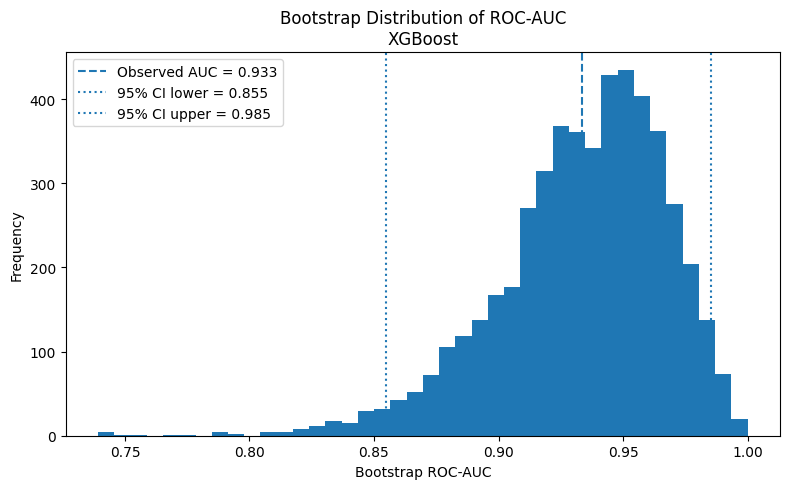



STEP 8 COMPLETED

Bootstrap resampling was used to estimate
95% confidence intervals for ROC-AUC.

Number of bootstrap samples: 5000

This provides an estimate of uncertainty
around model discrimination performance.



In [16]:
# ============================================================
# STEP 8: BOOTSTRAP 95% CONFIDENCE INTERVALS FOR ROC-AUC
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.utils import resample
from sklearn.metrics import roc_auc_score


# ------------------------------------------------------------
# 1. Store predictions from the independent test set
# ------------------------------------------------------------

predictions = {
    "Logistic Regression": y_prob,
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb
}


# ------------------------------------------------------------
# 2. Bootstrap function
# ------------------------------------------------------------

def bootstrap_auc_ci(
    y_true,
    y_probability,
    n_bootstrap=5000,
    confidence=0.95,
    random_state=42
):

    rng = np.random.RandomState(
        random_state
    )

    y_true = np.asarray(y_true)
    y_probability = np.asarray(y_probability)

    auc_values = []

    n = len(y_true)

    for i in range(n_bootstrap):

        # Sample test observations with replacement
        indices = rng.randint(
            0,
            n,
            n
        )

        y_sample = y_true[
            indices
        ]

        prob_sample = y_probability[
            indices
        ]

        # AUC cannot be calculated if bootstrap sample
        # contains only one class
        if len(np.unique(y_sample)) < 2:
            continue

        auc = roc_auc_score(
            y_sample,
            prob_sample
        )

        auc_values.append(
            auc
        )

    auc_values = np.array(
        auc_values
    )

    alpha = 1 - confidence

    lower = np.percentile(
        auc_values,
        100 * (alpha / 2)
    )

    upper = np.percentile(
        auc_values,
        100 * (1 - alpha / 2)
    )

    return (
        auc_values,
        lower,
        upper
    )


# ------------------------------------------------------------
# 3. Calculate bootstrap CIs
# ------------------------------------------------------------

bootstrap_results = []

bootstrap_distributions = {}

for name, probability in predictions.items():

    auc_distribution, lower, upper = (
        bootstrap_auc_ci(
            y_test,
            probability,
            n_bootstrap=5000,
            confidence=0.95,
            random_state=42
        )
    )

    observed_auc = roc_auc_score(
        y_test,
        probability
    )

    bootstrap_distributions[name] = (
        auc_distribution
    )

    bootstrap_results.append({

        "Model": name,

        "Observed_AUC":
            observed_auc,

        "Bootstrap_Mean_AUC":
            auc_distribution.mean(),

        "95%_CI_Lower":
            lower,

        "95%_CI_Upper":
            upper,

        "Bootstrap_SD":
            auc_distribution.std()

    })


# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

bootstrap_table = pd.DataFrame(
    bootstrap_results
)

print("\n========== BOOTSTRAP AUC RESULTS ==========")

display(
    bootstrap_table.round(4)
)


# ------------------------------------------------------------
# 5. Plot bootstrap distributions
# ------------------------------------------------------------

for name, distribution in bootstrap_distributions.items():

    plt.figure(figsize=(8, 5))

    plt.hist(
        distribution,
        bins=40
    )

    observed = roc_auc_score(
        y_test,
        predictions[name]
    )

    lower = bootstrap_table.loc[
        bootstrap_table["Model"] == name,
        "95%_CI_Lower"
    ].values[0]

    upper = bootstrap_table.loc[
        bootstrap_table["Model"] == name,
        "95%_CI_Upper"
    ].values[0]

    plt.axvline(
        observed,
        linestyle="--",
        label=f"Observed AUC = {observed:.3f}"
    )

    plt.axvline(
        lower,
        linestyle=":",
        label=f"95% CI lower = {lower:.3f}"
    )

    plt.axvline(
        upper,
        linestyle=":",
        label=f"95% CI upper = {upper:.3f}"
    )

    plt.xlabel(
        "Bootstrap ROC-AUC"
    )

    plt.ylabel(
        "Frequency"
    )

    plt.title(
        f"Bootstrap Distribution of ROC-AUC\n{name}"
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("STEP 8 COMPLETED")
print("=" * 60)

print("""
Bootstrap resampling was used to estimate
95% confidence intervals for ROC-AUC.

Number of bootstrap samples: 5000

This provides an estimate of uncertainty
around model discrimination performance.
""")